# Guided-wave impact localization
## 1. Problem
Recover105 controlled impact positions from real six-sensor relative arrivals in three changed operating conditions. Independent REF positions calibrate the wave-travel relation. The selected published baseline is RBF multitask Gaussian regression, not the unavailable proprietary composite-kernel/model-averaging method. True test positions are used only for this maintainer evaluation; they never enter inference. All units below are physical millimetres or seconds.

In [1]:
from pathlib import Path
import sys,time,json,subprocess
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
T=Path.cwd()
if T.name=='notebooks':T=T.parent
sys.path.insert(0,str(T));torch.set_num_threads(1)
from src.preprocessing import load,prepare
from src.solvers import reconstruct
from src.visualization import localization_comparison,uncertainty_ellipses
from src.physics_model import GP
D=load(T/'data/raw_data.npz')
with np.load(T/'evaluation/ground_truth.npz') as f:truth=f['reconstruction'][0].copy()
with np.load(T/'notebooks/reference_outputs/upstream_fit.npz') as f:source=f['reconstruction'].copy()
if source.ndim==4:source=source[0]
S=D['sensor_positions'];CASES=['HEI','ANG','TEM']
def table(headers,rows):display(Markdown('| '+' | '.join(headers)+' |\n|'+'|'.join(['---']*len(headers))+'|\n'+'\n'.join('| '+' | '.join(str(x) for x in r)+' |' for r in rows)))
def errors(p):
 e=np.linalg.norm(p-truth,axis=-1);return np.sqrt(np.mean(e*e,axis=1)),np.quantile(e,.9,axis=1),e.max(axis=1)


## 2. Data and independent calibration
The panel is290×200×4mm; the local instrumented rectangle is160×120mm. Sensor1 defines origin, sensor3 positive x and sensor4 positive y. A2MHz system supplies processed TDOAs. Each row subtracts its own earliest arrival. REF uses35 known calibration impacts. HEI increases drop height, ANG changes incidence and TEM is elevated temperature. The final article lists70°C while repository metadata list80°C; this unresolved metadata difference is disclosed, and no numeric temperature correction enters the conditional model. The full supplied float64 observations remain unrounded. Test row order is independent of REF and must not be inferred from grid order.

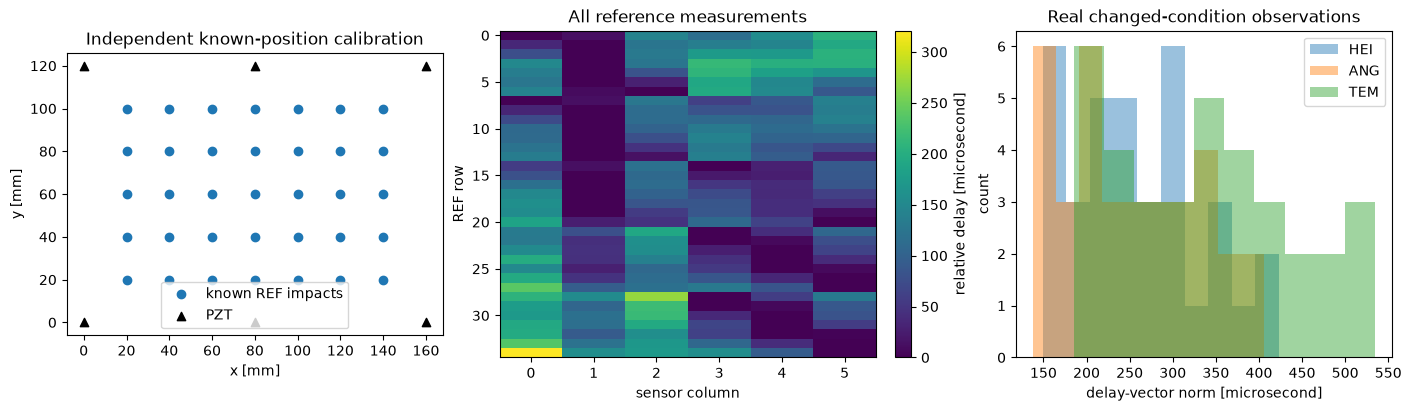

| Visible array | Shape | Unit |
|---|---|---|
| calibration_tdoa | (35, 6) | s |
| calibration_positions | (35, 2) | mm |
| sensor_positions | (6, 2) | mm |
| observations | (3, 35, 6) | s |

In [2]:
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained')
ax[0].scatter(D['calibration_positions'][:,0],D['calibration_positions'][:,1],label='known REF impacts');ax[0].scatter(S[:,0],S[:,1],marker='^',c='black',label='PZT');ax[0].set(xlabel='x [mm]',ylabel='y [mm]',title='Independent known-position calibration');ax[0].legend();ax[0].set_aspect('equal')
a=ax[1].imshow(D['calibration_tdoa']*1e6,aspect='auto');fig.colorbar(a,ax=ax[1],label='relative delay [microsecond]');ax[1].set(xlabel='sensor column',ylabel='REF row',title='All reference measurements')
for c in range(3):ax[2].hist(np.linalg.norm(D['observations'][c],axis=1)*1e6,bins=10,alpha=.45,label=CASES[c])
ax[2].set(xlabel='delay-vector norm [microsecond]',ylabel='count',title='Real changed-condition observations');ax[2].legend();plt.show()
table(['Visible array','Shape','Unit'],[(k,str(v.shape),'mm' if 'positions' in k else 's') for k,v in D.items()])


## 3. Physics and conditional inverse mathematics
For location $r$, sensor position $s_j$, travel time $T$ and error $e_j$,
$$
d_j=T(r,s_j)-\min_k T(r,s_k)+e_j,\qquad u=d/\lVert d\rVert_2.
$$
Travel time is in seconds, coordinates in millimetres. No independent wave-speed field is supplied, so REF provides the response calibration. A common positive delay scale cancels in $u$; actual environmental changes need not be exactly such a scale.

For normalized inputs $u_i$, length scale $\ell$, rank-one factor $f$ and positive task variances $v$, define
$$
K_{ij}=\exp[-\lVert u_i-u_j\rVert^2/(2\ell^2)],\quad B=ff^T+\mathrm{diag}(v),\quad C=K\otimes B+\mathrm{diag}(n,n,\ldots).
$$
The coordinate-task order is x,y per sample. $B$ and noise variances $n$ have units mm²; means have units mm. Softplus transforms raw variances and length scale, with the original noise floors retained. For $N=35$, residual $r_Y=\mathrm{vec}(Y)-m$ and Cholesky factor $C=LL^T$,
$$
J=\frac{r_Y^TC^{-1}r_Y/2+\sum_i\log L_{ii}+N\log(2\pi)}{2N}.
$$
Posterior means are $m_*+C_{\mathrm{cross}}^TC^{-1}r_Y$; predictive covariance is $C_{**}-C_{\mathrm{cross}}^TC^{-1}C_{\mathrm{cross}}$. These equations are explicitly implemented with general tensor algebra. An analytic one-point/two-independent-task conditional and finite-difference gradients independently check the formulas.

In [3]:
with np.load(T/'test/fixtures/upstream_gp_stages.npz') as f:
 torch.manual_seed(0);m=GP();x,y,z=prepare(D);initial_error=np.max(np.abs(m.cov(x).detach().numpy()-f['output_initial_covariance']));loss_difference=float(m.nll(x,y).detach())-float(f['output_initial_negative_log_likelihood'])
table(['Independent original parity','Measured difference','Unit'],[['Initial covariance maximum',initial_error,'mm²'],['Initial normalized negative loglikelihood',loss_difference,'1']])


| Independent original parity | Measured difference | Unit |
|---|---|---|
| Initial covariance maximum | 3.5762787e-07 | mm² |
| Initial normalized negative loglikelihood | 0.0 | 1 |

## 4. Method and active reconstruction
Run all5000 original Adam calibration updates using local explicit covariance/likelihood/conditioning mathematics. Calibration is shared across conditions, so one identical training is reused for all105 query rows. The independent original run actually repeated5000 updates separately for each condition. This changes no learned calibration or inverse target. No test-coordinate labels or frozen fitted hyperparameters are used in this active computation.

Complete active standard seconds 9.754701200057752 all105 points


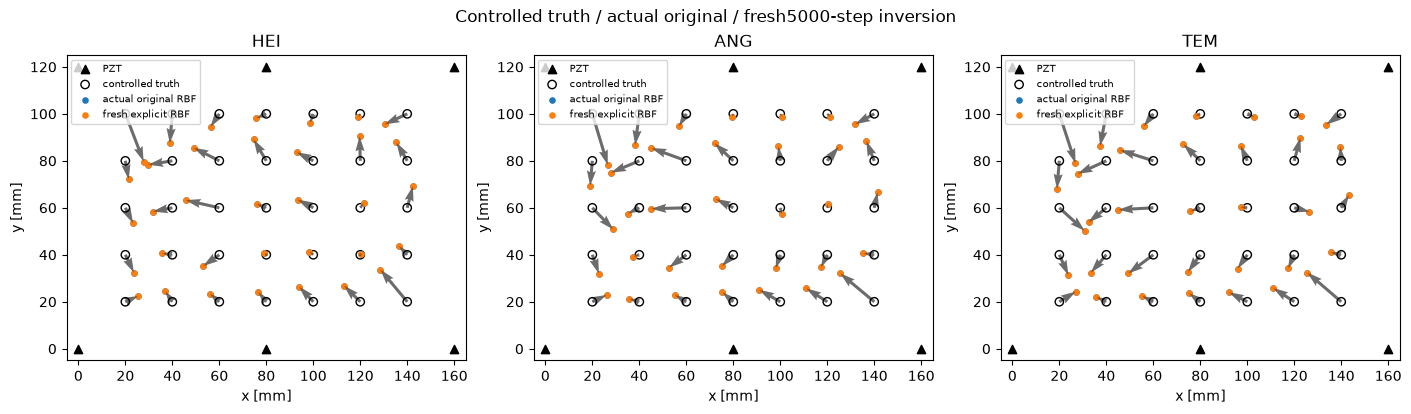

| Measurement | Condition | RMSE [mm] | P90 [mm] | maximum [mm] |
|---|---|---|---|---|
| actual original | HEI | 9.01040155 | 12.4615563 | 21.7530939 |
| actual original | ANG | 9.58318818 | 14.3108549 | 22.7290663 |
| actual original | TEM | 10.0935238 | 14.7375932 | 22.1459386 |
| fresh local | HEI | 9.01040069 | 12.4615679 | 21.7530827 |
| fresh local | ANG | 9.58318861 | 14.3108675 | 22.729036 |
| fresh local | TEM | 10.0935268 | 14.7375992 | 22.1459278 |

In [4]:
t=time.perf_counter();fresh,aux=reconstruct(D);elapsed=time.perf_counter()-t;p=fresh['reconstruction'][0];(T/'output').mkdir(exist_ok=True);np.savez(T/'output/reconstruction.npz',**fresh);print('Complete active standard seconds',elapsed,'all105 points')
fig=localization_comparison(truth,{'actual original RBF':source,'fresh explicit RBF':p},S,'Controlled truth / actual original / fresh5000-step inversion');plt.show()
rows=[]
for label,q in [('actual original',source),('fresh local',p)]:
 rm,pc,mx=errors(q)
 for c in range(3):rows.append([label,CASES[c],f'{rm[c]:.9g}',f'{pc[c]:.9g}',f'{mx[c]:.9g}'])
table(['Measurement','Condition','RMSE [mm]','P90 [mm]','maximum [mm]'],rows)


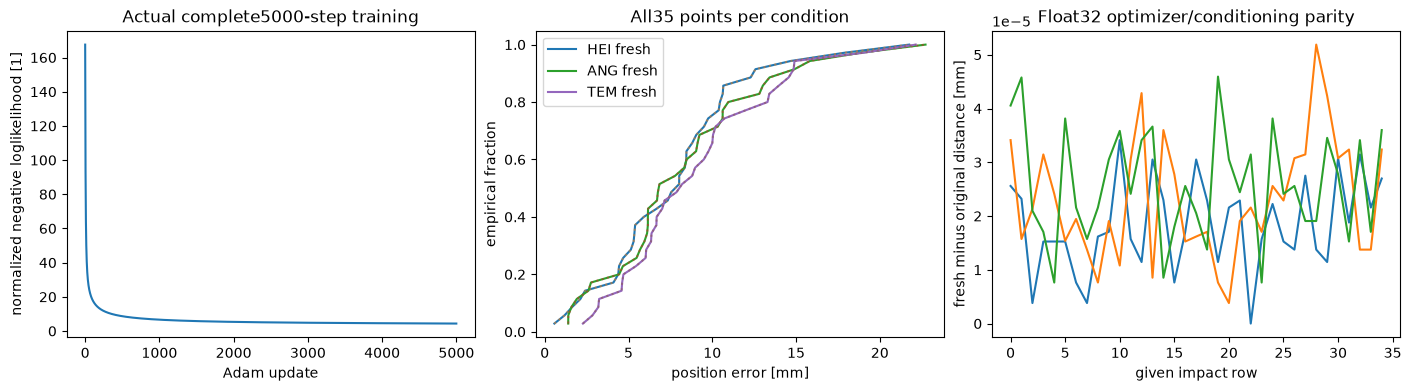

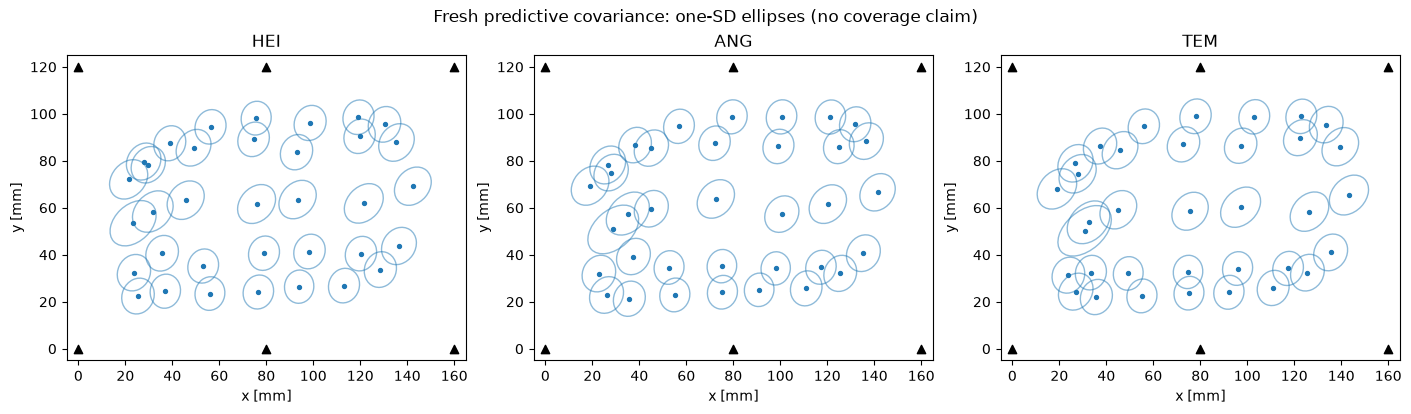

In [5]:
fig,ax=plt.subplots(1,3,figsize=(14,3.8),layout='constrained');ax[0].plot(aux['loss_history']);ax[0].set(xlabel='Adam update',ylabel='normalized negative loglikelihood [1]',title='Actual complete5000-step training')
for c in range(3):
 e=np.linalg.norm(p[c]-truth[c],axis=1);o=np.linalg.norm(source[c]-truth[c],axis=1);ax[1].plot(np.sort(e),np.arange(1,36)/35,label=CASES[c]+' fresh');ax[1].plot(np.sort(o),np.arange(1,36)/35,ls=':',alpha=.5)
ax[1].set(xlabel='position error [mm]',ylabel='empirical fraction',title='All35 points per condition');ax[1].legend()
diff=np.linalg.norm(p-source,axis=-1);ax[2].plot(diff.T);ax[2].set(xlabel='given impact row',ylabel='fresh minus original distance [mm]',title='Float32 optimizer/conditioning parity');plt.show()
uncertainty_ellipses(p,aux['covariance'],S);plt.show()


## 5. Comparisons, ablation and robustness
Actively fit the same5000-step RBF model with feature-wise REF-only standardization, and with four corner sensors after recomputing the earliest retained reference. These are additional measured-data inverse runs. Compare a nearest-reference-direction predictor without optimizing any test labels. Recondition the fresh standard model on scaled or perturbed queries; unchanged independent calibration is used. These comparisons concern robustness of this selected baseline, not the unavailable proprietary kernel methods. One-SD predictive ellipses are model uncertainty displays, not asserted95% empirical coverage. The original source ellipse normalization is approximately1.0204SD and is not a two-dimensional95% region.

Actual two additional5000-step fits seconds 18.449710899963975


| Actually computed method | Condition | RMSE [mm] | P90 [mm] | maximum [mm] |
|---|---|---|---|---|
| standard sample normalization | HEI | 9.010401 | 12.46157 | 21.75308 |
| standard sample normalization | ANG | 9.583189 | 14.31087 | 22.72904 |
| standard sample normalization | TEM | 10.09353 | 14.7376 | 22.14593 |
| feature standardization | HEI | 9.295703 | 12.79697 | 20.68605 |
| feature standardization | ANG | 9.429913 | 13.87111 | 20.85017 |
| feature standardization | TEM | 16.72657 | 24.03139 | 37.87482 |
| four corner PZTs | HEI | 18.40614 | 28.18622 | 45.11989 |
| four corner PZTs | ANG | 18.09748 | 27.37701 | 41.69477 |
| four corner PZTs | TEM | 19.18225 | 27.8219 | 47.30535 |
| nearest REF direction | HEI | 8.944272 | 20 | 20 |
| nearest REF direction | ANG | 8.280787 | 20 | 20 |
| nearest REF direction | TEM | 8.944272 | 20 | 20 |

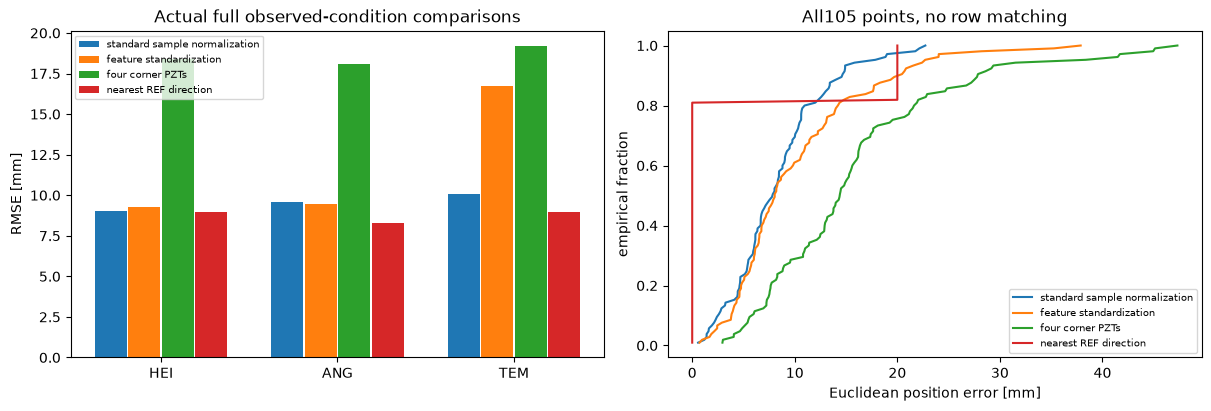

In [6]:
t=time.perf_counter();feature,_=reconstruct(D,normalization='feature');corners,_=reconstruct(D,sensors=[0,2,3,5]);comparisons={'standard sample normalization':p,'feature standardization':feature['reconstruction'][0],'four corner PZTs':corners['reconstruction'][0]}
x,y,z=prepare(D);nearest=np.argmin(((z.numpy()[:,None,:]-x.numpy()[None,:,:])**2).sum(-1),axis=1);comparisons['nearest REF direction']=D['calibration_positions'][nearest].reshape(3,35,2);print('Actual two additional5000-step fits seconds',time.perf_counter()-t)
rows=[]
for label,q in comparisons.items():
 rm,pc,mx=errors(q)
 for c in range(3):rows.append([label,CASES[c],f'{rm[c]:.7g}',f'{pc[c]:.7g}',f'{mx[c]:.7g}'])
table(['Actually computed method','Condition','RMSE [mm]','P90 [mm]','maximum [mm]'],rows)
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained');labels=list(comparisons)
for i,(label,q) in enumerate(comparisons.items()):ax[0].bar(np.arange(3)+.19*i,errors(q)[0],width=.18,label=label)
ax[0].set(xticks=np.arange(3)+.285,xticklabels=CASES,ylabel='RMSE [mm]',title='Actual full observed-condition comparisons');ax[0].legend(fontsize=7)
for label,q in comparisons.items():ax[1].plot(np.sort(np.linalg.norm(q-truth,axis=-1).ravel()),np.arange(1,106)/105,label=label)
ax[1].set(xlabel='Euclidean position error [mm]',ylabel='empirical fraction',title='All105 points, no row matching');ax[1].legend(fontsize=7);plt.show()


| Query condition | maximum position change [mm] |
|---|---|
| Common positive delay scale1.3 | 3.982660869182797e-05 |
| 0.5 microsecond independent delay perturbation | 1.1169021199448474 |

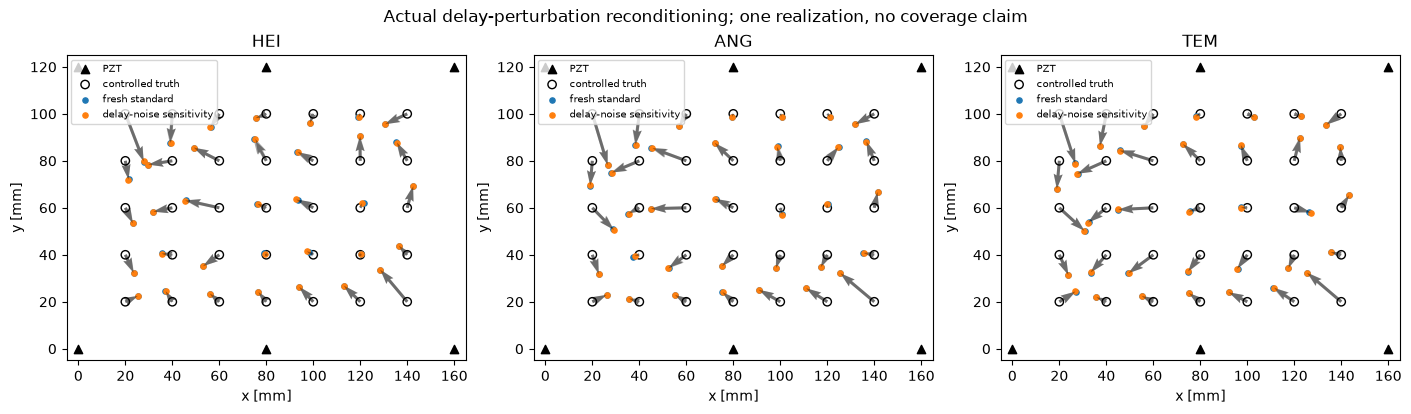

In [7]:
from src.preprocessing import prepare
scaled={**D,'observations':D['observations']*1.3};_,_,zs=prepare(scaled)
rng=np.random.default_rng(9);jittered=D['observations']+rng.normal(0,.5e-6,D['observations'].shape);jittered-=jittered.min(-1,keepdims=True);perturbed={**D,'observations':jittered};_,_,zj=prepare(perturbed)
with torch.no_grad():ms,_=aux['model'].predict(aux['train_x'],aux['train_y'],zs);mj,_=aux['model'].predict(aux['train_x'],aux['train_y'],zj)
scaled_p=ms.numpy().reshape(3,35,2);jitter_p=mj.numpy().reshape(3,35,2)
table(['Query condition','maximum position change [mm]'],[['Common positive delay scale1.3',np.linalg.norm(scaled_p-p,axis=-1).max()],['0.5 microsecond independent delay perturbation',np.linalg.norm(jitter_p-p,axis=-1).max()]])
fig=localization_comparison(truth,{'fresh standard':p,'delay-noise sensitivity':jitter_p},S,'Actual delay-perturbation reconditioning; one realization, no coverage claim');plt.show()


## 6. Results and conclusion
This selected RBF baseline recovers physical impact positions in three independently measured conditions using known REF calibration only. Remaining errors reflect finite calibration, arrival-time processing and condition transfer; no environmental travel-speed field has been independently recovered. Gaussian predictive uncertainty is conditional on its model and calibration, not an experimentally established confidence guarantee. Test truth directly assesses physical accuracy. All105 positions and all three error summaries are scored, without enforcing agreement with a particular Gaussian-process fit. The original novel composite-kernel/model-averaging method is unavailable and is not represented by a fabricated comparison.

In [8]:
r=subprocess.run([sys.executable,str(T/'evaluation/judge.py'),'--prediction',str(T/'output/reconstruction.npz'),'--report',str(T/'output/judge_report.json')],cwd=T,capture_output=True,text=True,encoding='utf8');print((T/'output/judge_report.json').read_text(encoding='utf8'));assert r.returncode==0,r.stderr


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "HEI_rmse_mm": 9.010400690291153,
    "HEI_p90_mm": 12.461567896703151,
    "HEI_maximum_mm": 21.753082727273945,
    "ANG_rmse_mm": 9.583188612194729,
    "ANG_p90_mm": 14.310867530288277,
    "ANG_maximum_mm": 22.729035959623253,
    "TEM_rmse_mm": 10.093526813095012,
    "TEM_p90_mm": 14.737599210344579,
    "TEM_maximum_mm": 22.145927783293036
  },
  "thresholds": {
    "HEI_rmse_mm": {
      "comparison": "<=",
      "boundary": 9.911441708925652
    },
    "HEI_p90_mm": {
      "comparison": "<=",
      "boundary": 13.707711875202772
    },
    "HEI_maximum_mm": {
      "comparison": "<=",
      "boundary": 23.928403343978424
    },
    "ANG_rmse_mm": {
      "comparison": "<=",
      "boundary": 10.541506998768554
    },
    "ANG_p90_mm": {
      "comparison": "<=",
      "boundary": 15.741940386879428
    },
    "ANG_maximum_mm": {
      "comparison": "<=",
      "boundary": 25.001972910340207
    },
    "TEM_rmse_mm": 